# Modelo de referencia

Implementa y evalúa un DummyClassifier como línea base.

In [1]:
import sys; sys.path.append("..")   # para poder importar desde src/
from pathlib import Path
import pandas as pd
from src.evaluate import compute_metrics, save_metrics

SEED = 42
DATA_DIR = Path("..") / "data" / "processed"

## 1. Carga de datos

Se leen los CSV generados en `01_eda.ipynb`. No se vuelve a dividir ni a preprocesar:
todos los modelos usan el mismo split de entrenamiento/prueba (80/20 estratificado, semilla 42)
para que las métricas sean comparables.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

X_train, y_train = train["clean"], train["label"]   # 1 = positivo, 0 = negativo
X_test, y_test = test["clean"], test["label"]

print("Train:", train.shape, "| Test:", test.shape)
print("Clases en train:", y_train.value_counts().to_dict())
print("Clases en test: ", y_test.value_counts().to_dict())

Train: (800, 7) | Test: (200, 7)
Clases en train: {1: 400, 0: 400}
Clases en test:  {1: 100, 0: 100}


In [4]:
train[["text", "clean", "label"]].head()

,text,clean,label
0,OH MY GOD OH MY GOD CONGRATS!!!!,oh god oh god congrats,1
1,I'm also a human being but I can't think of an...,also human can't think reason would physically...,0
2,"I wish, have to wait 3 weeks",wish wait 3 weeks,1
3,It was on a washed out road in the at 2am. Whi...,washed road 2 makes even worse never towing vic,0
4,[NAME] did a photo shoot with the first presid...,[name] photo shoot first presidency hilarious,1


## 2. DummyClassifier: estrategias

El `DummyClassifier` ignora el texto y predice con una regla fija basada solo en las etiquetas de entrenamiento.
Se entrenan las cuatro estrategias de scikit-learn para ver cómo se comporta el "azar" como línea base.

In [3]:
from sklearn.dummy import DummyClassifier

STRATEGIES = ["most_frequent", "prior", "stratified", "uniform"]

models, preds = {}, {}
for strategy in STRATEGIES:
    model = DummyClassifier(strategy=strategy, random_state=SEED)
    model.fit(X_train, y_train)               # solo "aprende" la distribución de y_train
    models[strategy] = model
    preds[strategy] = model.predict(X_test)   # predicción sobre el test de 200 comentarios

# Qué predice cada estrategia: conteo de clases predichas
for strategy, y_pred in preds.items():
    print(f"{strategy:<14} -> {pd.Series(y_pred).value_counts().to_dict()}")

most_frequent  -> {0: 200}
prior          -> {0: 200}
stratified     -> {1: 102, 0: 98}
uniform        -> {0: 100, 1: 100}


## 3. Métricas por estrategia

Se evalúa cada estrategia sobre el conjunto de prueba (200 comentarios, 100 por clase) con
accuracy, precision, recall, F1 y kappa de Cohen. La clase positiva es 1 (comentario positivo).

In [4]:
rows = []
for strategy, y_pred in preds.items():
    rows.append({"strategy": strategy, **compute_metrics(y_test, y_pred)})

results = pd.DataFrame(rows).set_index("strategy")
results.round(3)

,accuracy,precision,recall,f1,kappa
strategy,,,,,
most_frequent,0.50,0.00,0.00,0.000,0.00
prior,0.50,0.00,0.00,0.000,0.00
stratified,0.50,0.50,0.51,0.505,0.00
uniform,0.48,0.48,0.48,0.480,-0.04


**Observaciones preliminares**

- Todas las estrategias quedan cerca de 50% de accuracy, como se espera con clases balanceadas.
- `most_frequent` y `prior` predicen siempre la clase negativa, por eso su precision, recall y F1 son 0 para la clase positiva.
- El kappa ronda 0 en todos los casos: ninguna estrategia supera al azar.

## 4. Matrices de confusión

Cada matriz muestra los aciertos y errores de la estrategia sobre el conjunto de prueba
(filas = clase real, columnas = clase predicha). Las figuras se guardan en `outputs/figures/`.

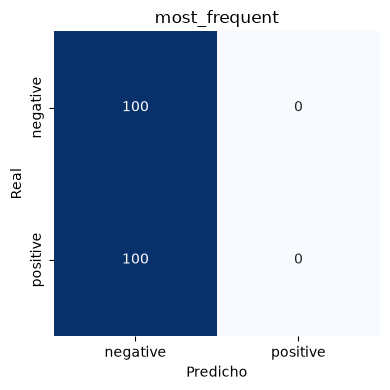

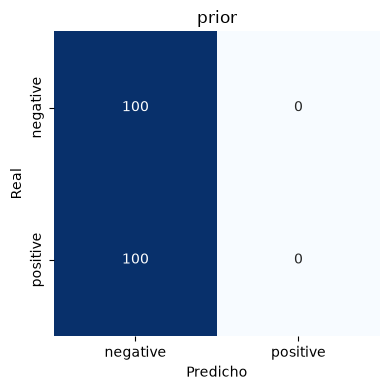

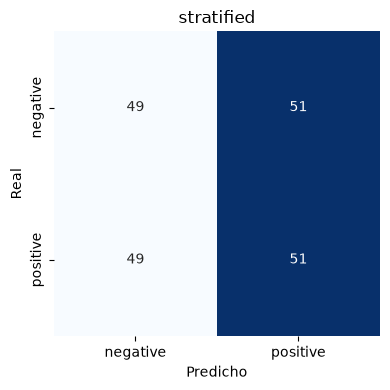

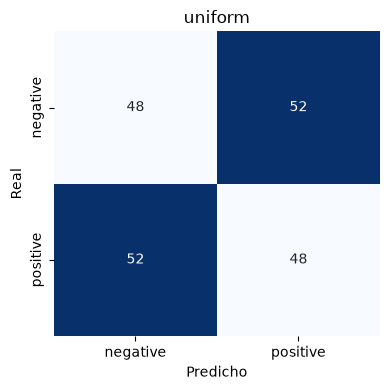

In [5]:
from src.visualize import plot_confusion_matrix

for strategy, y_pred in preds.items():
    plot_confusion_matrix(y_test, y_pred, title=strategy,name=f"baseline_confusion_{strategy}.png")